(<Axes: >, <matplotlib.image.AxesImage at 0x1fdac80c110>)

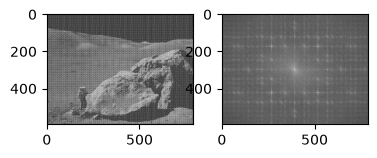

In [49]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
rows, cols = img.shape
centerX, centerY = int(rows / 2), int(cols / 2)

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))
plt.subplot(231), plt.imshow(img, cmap='gray')
plt.subplot(232), plt.imshow(magnitude_spectrum, cmap='gray')


***1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса***

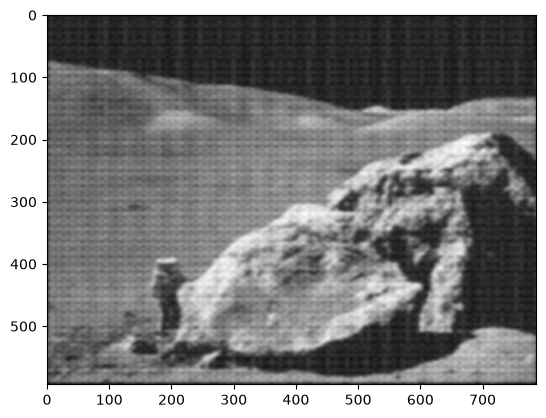

In [54]:
x = np.arange(0, cols) - centerY
y = np.arange(0, rows) - centerX
X, Y = np.meshgrid(x, y)
D2 = X**2 + Y**2

D0 = 40 # Пробовал разные радиусы, влияние несущественно либо все только хуже
H = np.exp(-D2 / (2 * D0**2))

mask_gauss = np.zeros((rows, cols, 2), np.float32)
mask_gauss[:, :, 0] = H
mask_gauss[:, :, 1] = H

dft_gauss = dft_shift * mask_gauss
f_ishift_gauss = np.fft.ifftshift(dft_gauss)
img_gauss_complex = cv.idft(f_ishift_gauss)
img_gauss = cv.magnitude(img_gauss_complex[:,:,0], img_gauss_complex[:,:,1])
img_gauss = cv.normalize(img_gauss, None, 0, 255, cv.NORM_MINMAX)
plt.imshow(img_gauss, cmap='gray')

***2.Реализуйте вычисление свертки с помощью преобразования Фурье***

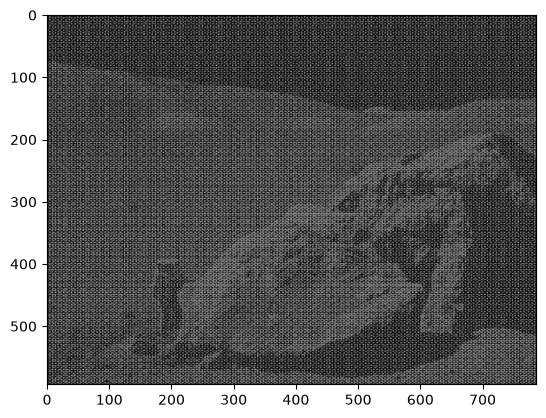

In [57]:
kernel = np.array([[ 0, -1,  0],
                   [-1,  6, -1],
                   [ 0, -1,  0]], np.float32)

padded_kernel = np.zeros_like(img, dtype=np.float32)
padded_kernel[:kernel.shape[0], :kernel.shape[1]] = kernel

dft_kernel = cv.dft(padded_kernel, flags=cv.DFT_COMPLEX_OUTPUT)
dft_mult = cv.mulSpectrums(dft, dft_kernel, 0)
img_conv = cv.idft(dft_mult)
img_conv = cv.magnitude(img_conv[:,:,0], img_conv[:,:,1])
plt.imshow(img_conv, cmap='gray')

***Реализуйте удаление периодического шума с помощью преобразования Фурье***

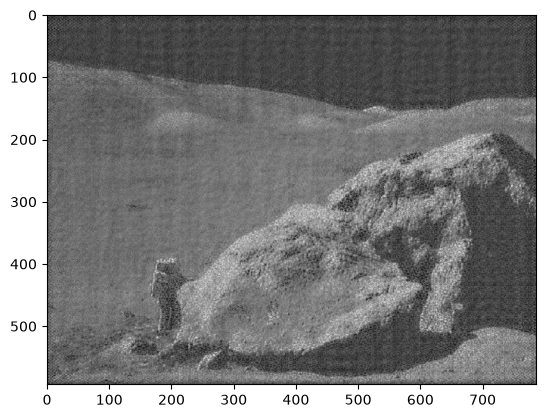

In [55]:
mask_notch = np.ones((rows, cols, 2), np.float32)
threshold = np.percentile(magnitude_spectrum, 98)

mask_notch[magnitude_spectrum > threshold] = 0

mask_notch[centerX-30:centerX+30, centerY-30:centerY+30, :] = 1

dft_notch = dft_shift * mask_notch
img_notch = cv.idft(np.fft.ifftshift(dft_notch))
img_notch = cv.magnitude(img_notch[:,:,0], img_notch[:,:,1])
plt.imshow(img_notch, cmap='gray')

(<Axes: >, <matplotlib.image.AxesImage at 0x1fdac258aa0>)

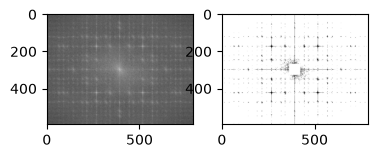

In [56]:
plt.subplot(231), plt.imshow(magnitude_spectrum, cmap='gray')
plt.subplot(232), plt.imshow(mask_notch[:,:,0], cmap='gray')